> Nama : Arrahim

> NIM : 055638437

# Tugas 3 Implementasi Unsupervised Learning: Segmentasi Pelanggan Berdasarkan Analisis Kepribadian (*Customer Personality Analysis*)

## 1. Latar Belakang
Dalam persaingan bisnis ritel modern, pendekatan pemasaran secara massal (*one-size-fits-all*) sering kali tidak efisien karena setiap pelanggan memiliki daya beli, komposisi keluarga, dan preferensi produk yang berbeda. Perusahaan ritel memerlukan pemahaman mendalam mengenai karakteristik pelanggannya agar dapat merancang strategi promosi yang tepat sasaran.

Melalui teknik *Machine Learning* kategori *Unsupervised Learning* dengan algoritma **K-Means Clustering**, perusahaan dapat mengelompokkan ribuan data historis pelanggan secara otomatis ke dalam beberapa segmen berdasarkan kemiripan profil demografi dan perilaku transaksi. Sebelum pemodelan dilakukan, diperlukan tahapan *data preprocessing* (penanganan *missing value*, *encoding*, dan *scaling*) mengingat data mentah memiliki tipe fitur campuran (numerik dan kategorikal) serta rentang skala yang berbeda jauh.

## 2. Rumusan Masalah
1. Bagaimana menangani *missing value*, fitur kategorikal, dan perbedaan skala numerik pada dataset *Customer Personality Analysis* (`cpa.csv`) agar siap diproses oleh algoritma berbasis jarak?
2. Berapa jumlah klaster ($k$) optimal untuk mengelompokkan pelanggan berdasarkan evaluasi metode *Elbow* dan *Silhouette Score*?
3. Bagaimana karakteristik profil masing-masing klaster pelanggan yang terbentuk dan rekomendasi strategi bisnis yang tepat untuk setiap segmen?

## 3. Tujuan Praktikum
1. Menerapkan tahapan *preprocessing* data meliputi imputasi *missing value* dengan nilai median, transformasi fitur kategorikal menggunakan *One-Hot Encoding*, dan standardisasi fitur numerik dengan *StandardScaler*.
2. Mengimplementasikan algoritma K-Means Clustering serta mengevaluasi jumlah klaster optimal menggunakan *Elbow Method* dan *Silhouette Score*.
3. Memvisualisasikan hasil pengelompokan dalam dimensi 2D menggunakan *Principal Component Analysis* (PCA) dan menyusun interpretasi bisnis yang bermakna (*meaningful*) dari tiap segmen pelanggan.


In [ ]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

**Step 1: Load Dataset**

In [ ]:
# Membaca dataset cpa.csv dengan delimiter tab (\t)
df = pd.read_csv('cpa.csv', sep='\t')

# Tampilkan 5 baris pertama
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


> Dataset `cpa.csv` berhasil dimuat dengan pemisah karakter tab (`\t`), terdiri dari **2.240 baris (pelanggan)** dan **29 kolom (fitur)**. Data mencakup informasi demografi (`Year_Birth`, `Education`, `Marital_Status`, `Income`), komposisi keluarga (`Kidhome`, `Teenhome`), riwayat nominal belanja (`MntWines`, `MntMeatProducts`, dll.), kanal pembelian, hingga respons terhadap kampanye pemasaran.


**Step 2: Lakukan Eksplorasi Awal**

In [ ]:
# Ringkasan tipe data dan struktur
print("=== Informasi Dataset ===")
print(df.info())

# Cek nilai yang hilang (missing values)
print("\n=== Jumlah Missing Values ===")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Statistik deskriptif
df.describe()

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurc

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


> **Missing Values:** Ditemukan **24 nilai kosong (`NaN`)** yang hanya terdapat pada fitur `Income` (sekitar 1,07% dari total data), sedangkan 28 kolom lainnya lengkap (2.240 *non-null*).
> * **Distribusi & Skala Data:** Terdapat perbedaan rentang nilai yang sangat mencolok antar fitur numerik. Misalnya, `Income` memiliki nilai rata-rata 52.247 dengan nilai maksimum mencapai 666.666, sementara fitur seperti `Kidhome` berada pada rentang 0–2. Hal ini mengonfirmasi perlunya tahap *feature scaling* sebelum melakukan klastering.


**Step 3:Identifikasi Kolom Numerik dan Kategori**

In [ ]:
# Hapus kolom ID dan Dt_Customer karena tidak digunakan langsung untuk klastering
cols_to_drop = ['ID', 'Dt_Customer']
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# Pisahkan kolom numerik dan kategori
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()

print("Kolom Numerik:", num_cols)
print("Kolom Kategori:", cat_cols)

Kolom Numerik: ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']
Kolom Kategori: ['Education', 'Marital_Status']


> Kolom `ID` dan `Dt_Customer` dihapus (*drop*) karena `ID` hanya merupakan nomor identitas acak yang tidak merepresentasikan perilaku pelanggan, sedangkan `Dt_Customer` adalah data tanggal pendaftaran mentah. Dari 27 fitur tersisa, teridentifikasi **25 kolom numerik** dan **2 kolom kategorikal** (`Education` dan `Marital_Status`).


**Step 4: Imputasi Missing Value**

In [ ]:
# Imputasi kolom numerik (seperti kolom Income yang memiliki nilai hilang) dengan median
imputer_num = SimpleImputer(strategy='median')
df_clean[num_cols] = imputer_num.fit_transform(df_clean[num_cols])

# Imputasi kategori dengan modus jika ada
if cat_cols:
    imputer_cat = SimpleImputer(strategy='most_frequent')
    df_clean[cat_cols] = imputer_cat.fit_transform(df_clean[cat_cols])

print("Sisa total missing value:", df_clean.isnull().sum().sum())

Sisa total missing value: 0


> Sebanyak 24 nilai yang hilang pada kolom `Income` telah diimputasi menggunakan nilai **median** (51.381,5). Pemilihan median dilakukan karena lebih tahan (*robust*) terhadap nilai ekstrem (*outlier*) pada data pendapatan dibandingkan nilai rata-rata (*mean*). Hasil pemeriksaan akhir menunjukkan sisa *missing value* berjumlah **0**.


**Step 5: Encoding Variable Kategorikal (Education dan Marital Status)**

In [ ]:
# Encoding variabel kategorikal (Education & Marital_Status)
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

if cat_cols:
    cat_encoded = encoder.fit_transform(df_clean[cat_cols])
    encoded_cat_cols = encoder.get_feature_names_out(cat_cols)
    df_cat_encoded = pd.DataFrame(cat_encoded, columns=encoded_cat_cols, index=df_clean.index)
else:
    df_cat_encoded = pd.DataFrame()

menggabungkan data numerik dan hasil encoding

In [ ]:
# Menggabungkan fitur numerik yang disiapkan dan hasil One-Hot Encoding
df_final = pd.concat([df_clean[num_cols], df_cat_encoded], axis=1)
df_final.head()

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


> Kedua fitur kategorikal (`Education` dengan 5 kategori unik dan `Marital_Status` dengan 8 kategori unik) berhasil dikonversi menjadi **13 kolom biner baru** melalui *One-Hot Encoding*. Setelah digabungkan kembali dengan 25 kolom numerik awal, dataset final (`df_final`) memiliki dimensi **2.240 baris × 38 kolom** yang seluruhnya sudah berbentuk numerik.


**Step 6: Scaling Data**

In [ ]:
# Standardisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final)

> Seluruh 38 fitur telah distandardisasi menggunakan `StandardScaler` sehingga setiap kolom memiliki nilai rata-rata ($\mu$) = 0 dan standar deviasi ($\sigma$) = 1. Tahap ini memastikan fitur berskala puluhan ribu seperti `Income` tidak mendominasi perhitungan jarak Euclidean pada algoritma K-Means.


**Step 7: Menentukan Jumlah Klaster Optimal (Elbow + Sihouette)**

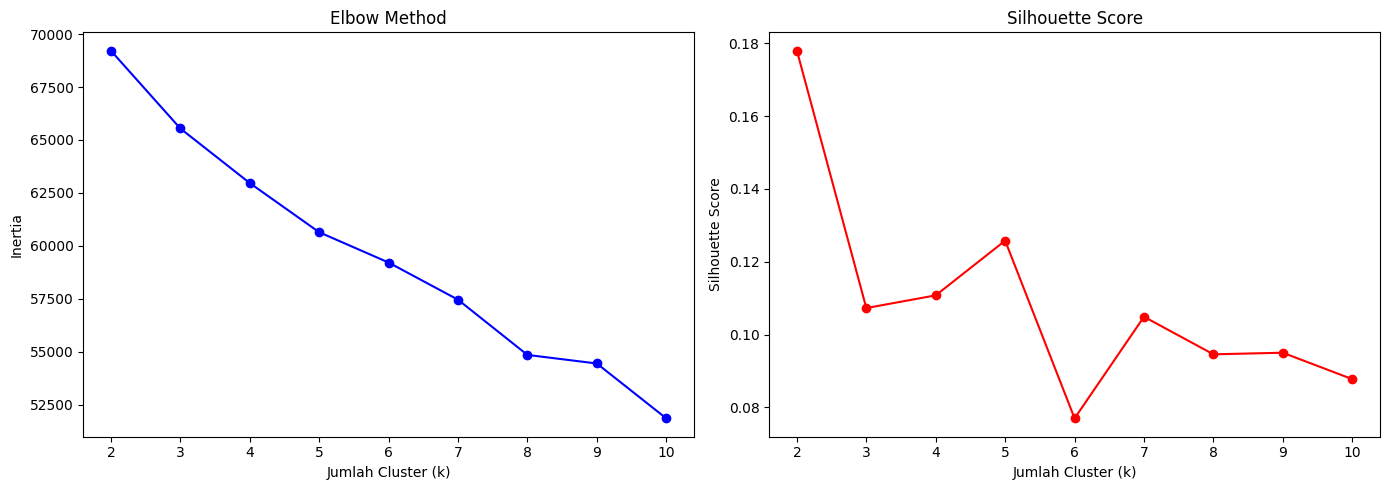

In [ ]:
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot grafik Elbow dan Silhouette Score
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, 'bo-')
plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, 'ro-')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

> * **Elbow Method:** Penurunan nilai *inertia* terlihat tajam dari $k=2$ ke $k=3$, kemudian mulai melandai secara bertahap setelah titik tersebut.
> * **Silhouette Score:** Meskipun skor tertinggi berada pada $k=2$ (0,178), pembagian menjadi dua kelompok terlalu umum untuk kebutuhan segmentasi pasar. Oleh karena itu, **$k=3$** (skor 0,108) dipilih sebagai jumlah klaster optimal karena memberikan keseimbangan antara kepadatan klaster dan keragaman segmen bisnis.


**Step 8: Memilih K Optimal dan Klasterisasi**

In [ ]:
# Menentukan k optimal (misal: k=3)
k_optimal = 3

kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Masukkan hasil klaster kembali ke DataFrame utama
df['Cluster'] = clusters
df_clean['Cluster'] = clusters

**Step 9: Visualisasi Klaster dengan PCA 2D**

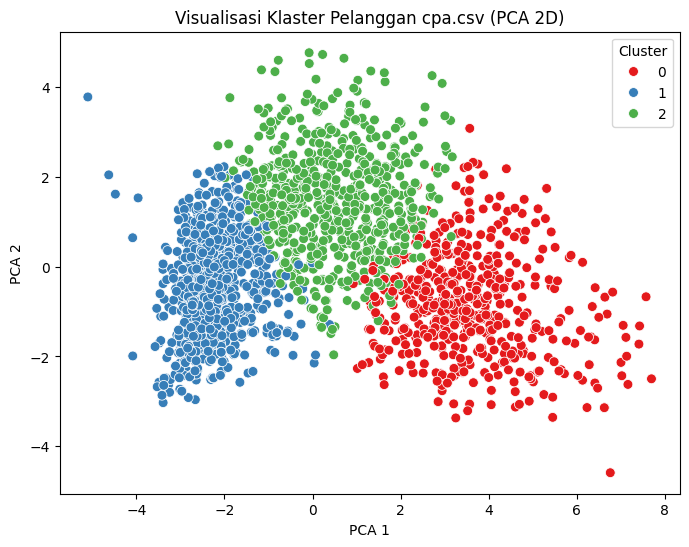

In [ ]:
# Reduksi dimensi fitur menggunakan PCA 2D untuk visualisasi
pca = PCA(n_components=2)
pca_features = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(pca_features, columns=['PCA1', 'PCA2'])
df_pca['Cluster'] = clusters

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=df_pca, palette='Set1', s=50)
plt.title('Visualisasi Klaster Pelanggan cpa.csv (PCA 2D)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()

> Dataset berdimensi 38 berhasil diproyeksikan ke dalam 2 komponen utama (`PCA 1` dan `PCA 2`). Secara visual, ketiga klaster terpisah dengan sangat jelas: **Cluster 0 (merah)** terkonsentrasi di sisi kanan (area positif PCA 1), **Cluster 1 (biru)** berkumpul rapat di sisi kiri bawah, dan **Cluster 2 (hijau)** menempati area tengah hingga atas. Ini membuktikan segmentasi $k=3$ memiliki pemisahan pola yang solid.


**Step 10: Profiling Cluster (rata-rata fitur per player)**

In [ ]:
# Rata-rata nilai fitur numerik per cluster
cluster_profile = df_clean.groupby('Cluster')[num_cols].mean()
cluster_profile.T

Cluster,0,1,2
Year_Birth,1968.760714,1971.902174,1964.152695
Income,77440.552679,34537.727767,57925.411677
Kidhome,0.041071,0.815217,0.220060
Teenhome,0.155357,0.433794,0.910180
Recency,49.596429,49.241107,48.501497
MntWines,612.944643,38.957510,446.320359
MntFruits,68.978571,4.857708,23.013473
MntMeatProducts,467.098214,22.594862,134.022455
MntFishProducts,100.601786,6.945652,30.974551
MntSweetProducts,71.082143,4.942688,23.672156


Visualisasi Distribusi/Profile Klaster

/tmp/ipykernel_1716/3096983045.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cluster', y='Income', data=df_clean, ax=axes[0, 0], palette='Set1')
/tmp/ipykernel_1716/3096983045.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cluster', y='MntWines', data=df_clean, ax=axes[0, 1], palette='Set1')
/tmp/ipykernel_1716/3096983045.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cluster', y='MntMeatProducts', data=df_clean, ax=axes[1, 0], palette='Set1')
/tmp/ipykernel_1716/3096983045.py:13: FutureWarning: 

Passing `palette` 

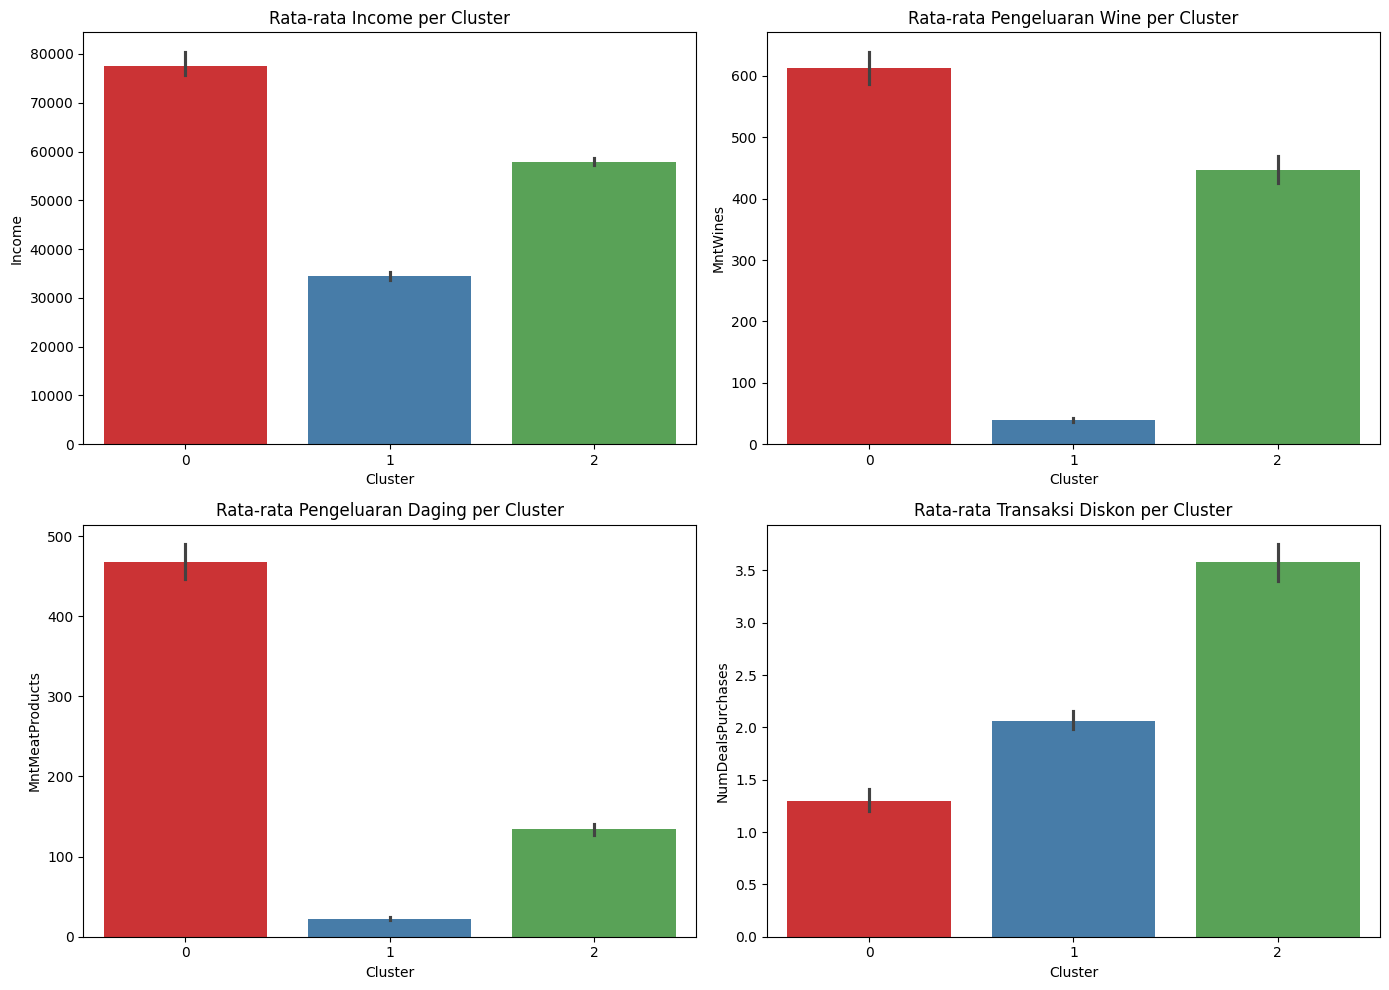

In [ ]:
# Visualisasi perbandingan fitur kunci antar cluster
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.barplot(x='Cluster', y='Income', data=df_clean, ax=axes[0, 0], palette='Set1')
axes[0, 0].set_title('Rata-rata Income per Cluster')

sns.barplot(x='Cluster', y='MntWines', data=df_clean, ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title('Rata-rata Pengeluaran Wine per Cluster')

sns.barplot(x='Cluster', y='MntMeatProducts', data=df_clean, ax=axes[1, 0], palette='Set1')
axes[1, 0].set_title('Rata-rata Pengeluaran Daging per Cluster')

sns.barplot(x='Cluster', y='NumDealsPurchases', data=df_clean, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Rata-rata Transaksi Diskon per Cluster')

plt.tight_layout()
plt.show()

> Berdasarkan tabel rata-rata fitur dan grafik perbandingan 4 indikator kunci (`Income`, `MntWines`, `MntMeatProducts`, dan `NumDealsPurchases`), terlihat kontras yang tajam antar segmen:
> * **Cluster 0** mendominasi pendapatan dan pengeluaran produk premium (*wine* & daging), namun paling jarang menggunakan diskon.
> * **Cluster 1** memiliki pendapatan dan tingkat belanja terendah di semua kategori.
> * **Cluster 2** berada pada tingkat pendapatan menengah dengan frekuensi pemanfaatan transaksi diskon tertinggi dibanding dua klaster lainnya.


## Simpulan dan Rekomendasi Bisnis

Berdasarkan hasil preprocessing, klasterisasi K-Means ($k=3$), reduksi dimensi PCA, serta analisis profiling fitur utama, diperoleh 3 segmen pelanggan dengan karakteristik dan rekomendasi strategi bisnis sebagai berikut:

### 1. Cluster 0: Premium / VIP Customers (Sultan)
* **Karakteristik:** Pendapatan rata-rata tertinggi (77.440), pengeluaran belanja *wine* dan produk daging sangat dominan, serta sangat jarang menggunakan kupon diskon. Sangat responsif terhadap kampanye promosi perusahaan (30.18%).
* **Rekomendasi Bisnis:**
  * Implementasikan program loyalitas kelas atas (VIP Loyalty Program) dan penawaran *exclusivity membership*.
  * Tawarkan produk edisi terbatas (*limited edition*) atau paket *gourmet/premium line* tanpa perlu bergantung pada potongan harga.

### 2. Cluster 1: Low-Income / Budget Shoppers (Pelanggan Hemat)
* **Karakteristik:** Pendapatan rata-rata paling rendah (34.537) dan mayoritas memiliki anak kecil di rumah. Total nilai belanja pada semua kategori produk tergolong sangat rendah.
* **Rekomendasi Bisnis:**
  * Berikan promosi berorientasi nilai seperti *bundling* produk kebutuhan pokok keluarga berharga ekonomis.
  * Gunakan kupon diskon langsung dan penawaran *cashback* untuk mendorong keputusan pembelian.

### 3. Cluster 2: Middle-Class / Deal-Seekers (Keluarga Menengah Pemburu Diskon)
* **Karakteristik:** Pendapatan tingkat menengah (57.925) dengan mayoritas memiliki anak remaja. Sangat aktif memanfaatkan promo/diskon (frekuensi *NumDealsPurchases* tertinggi) dan rutin berbelanja via situs web.
* **Rekomendasi Bisnis:**
  * Optimalkan strategi *email marketing* dan *push notification* berisi info *Flash Sale* atau promo diskon *online*.
  * Buat program *cashback* berbasis ambang batas belanja (misal: "Diskon 20% untuk minimal belanja Rp 500.000") untuk menaikkan nilai keranjang belanja mereka.
